# House Price Prediction System
## 7th Semester Machine Learning Capstone Project

### Overview
This notebook presents the end-to-end data science lifecycle for predicting residential house prices.
- **Exploratory Data Analysis (EDA)**
- **Data Preprocessing & Cleaning**
- **Domain Feature Engineering**
- **Comparative Regression Modeling** (Linear Regression, Decision Tree, Random Forest, Gradient Boosting, XGBoost)
- **XGBoost Hyperparameter Tuning** via 5-Fold Cross-Validation
- **Model Evaluation** using MAE, RMSE, and R² Score
- **Production Pipeline Serialization** (model.pkl)


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Ensure project root is in sys.path
BASE_DIR = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == 'notebooks' else os.path.abspath(os.getcwd())
if BASE_DIR not in sys.path:
    sys.path.insert(0, BASE_DIR)

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Set plotting style
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 6)
print('Libraries loaded successfully!')


Libraries loaded successfully!


## 1. Data Loading & Inspection


In [2]:
data_path = os.path.join(BASE_DIR, 'data', 'house_data.csv')
df = pd.read_csv(data_path)
print(f'Dataset Shape: {df.shape}')
df.head()


Dataset Shape: (545, 13)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [3]:
# Check data types and missing values
print('--- Dataset Info ---')
df.info()

print('\n--- Missing Values Count ---')
print(df.isnull().sum())

print('\n--- Duplicate Records Count ---')
print(f'Duplicates: {df.duplicated().sum()}')


--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB

--- Missing Values Count ---
price               0
area                0
bedrooms            0
bathrooms           0
stories        

In [4]:
# Summary statistics for numerical variables
df.describe().T


,count,mean,std,min,25%,50%,75%,max
price,545.0,4.766729e+06,1.870440e+06,1750000.0,3430000.0,4340000.0,5740000.0,13300000.0
area,545.0,5.150541e+03,2.170141e+03,1650.0,3600.0,4600.0,6360.0,16200.0
bedrooms,545.0,2.965138e+00,7.380639e-01,1.0,2.0,3.0,3.0,6.0
bathrooms,545.0,1.286239e+00,5.024696e-01,1.0,1.0,1.0,2.0,4.0
stories,545.0,1.805505e+00,8.674925e-01,1.0,1.0,2.0,2.0,4.0
parking,545.0,6.935780e-01,8.615858e-01,0.0,0.0,0.0,1.0,3.0


## 2. Exploratory Data Analysis (EDA)
### 2.1 Target Variable (Price) Distribution


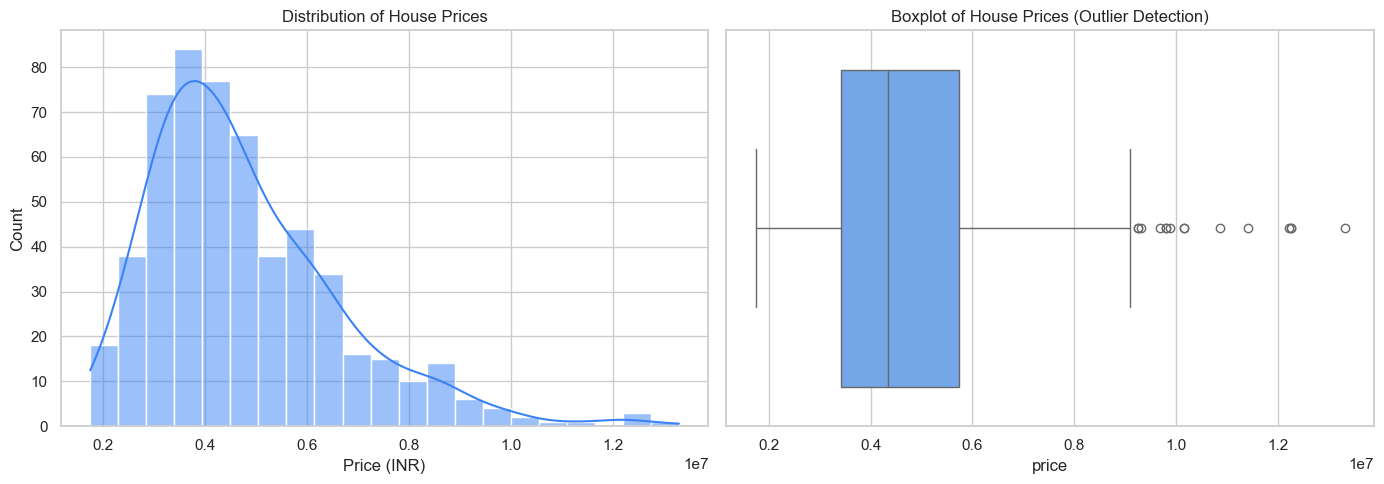

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['price'], kde=True, ax=axes[0], color='#3b82f6')
axes[0].set_title('Distribution of House Prices')
axes[0].set_xlabel('Price (INR)')

sns.boxplot(x=df['price'], ax=axes[1], color='#60a5fa')
axes[1].set_title('Boxplot of House Prices (Outlier Detection)')
plt.tight_layout()
plt.show()


### 2.2 Feature Relationships with Price


C:\Users\dwive\AppData\Local\Temp\ipykernel_28568\19400578.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='bedrooms', y='price', ax=axes[0, 1], palette='Blues')
C:\Users\dwive\AppData\Local\Temp\ipykernel_28568\19400578.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='bathrooms', y='price', ax=axes[1, 0], palette='Greens')
C:\Users\dwive\AppData\Local\Temp\ipykernel_28568\19400578.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='furnishingstatus', y='price', ax=axes[1, 1], palette='Purples')


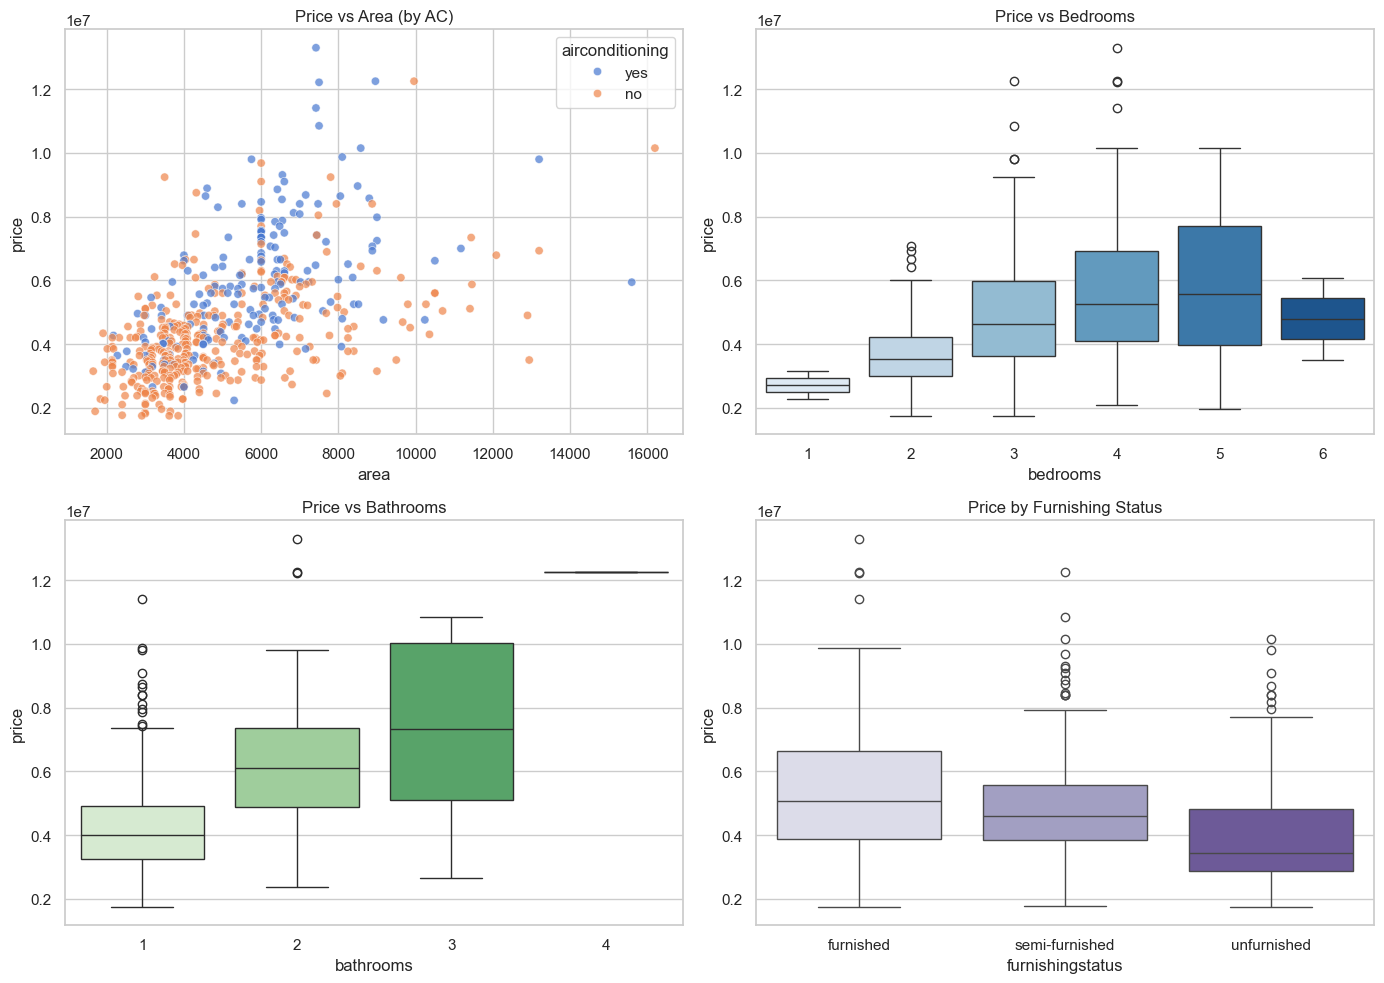

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Price vs Area
sns.scatterplot(data=df, x='area', y='price', hue='airconditioning', ax=axes[0, 0], alpha=0.7)
axes[0, 0].set_title('Price vs Area (by AC)')

# Price vs Bedrooms
sns.boxplot(data=df, x='bedrooms', y='price', ax=axes[0, 1], palette='Blues')
axes[0, 1].set_title('Price vs Bedrooms')

# Price vs Bathrooms
sns.boxplot(data=df, x='bathrooms', y='price', ax=axes[1, 0], palette='Greens')
axes[1, 0].set_title('Price vs Bathrooms')

# Price vs Furnishing Status
sns.boxplot(data=df, x='furnishingstatus', y='price', ax=axes[1, 1], palette='Purples')
axes[1, 1].set_title('Price by Furnishing Status')

plt.tight_layout()
plt.show()


### 2.3 Correlation Matrix for Numerical Features


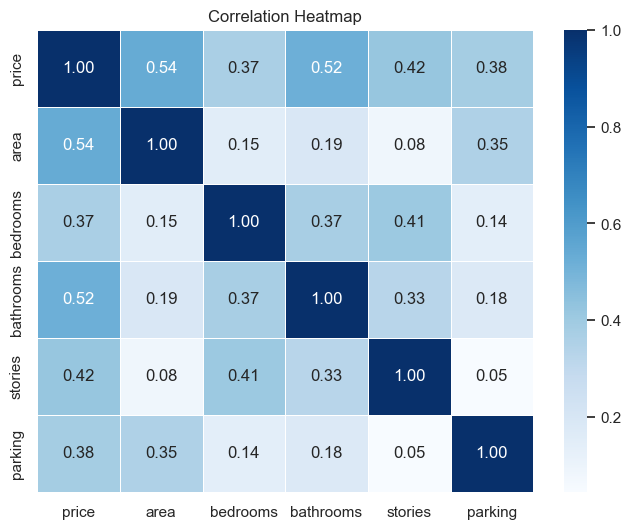

In [7]:
num_cols = ['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'parking']
corr = df[num_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='Blues', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()


## 3. Feature Engineering
We create three domain-derived features:
1. `total_rooms` = `bedrooms` + `bathrooms`
2. `area_per_room` = `area` / `total_rooms`
3. `bathroom_per_bedroom` = `bathrooms` / `bedrooms`


In [8]:
df_fe = df.copy()
df_fe['total_rooms'] = df_fe['bedrooms'] + df_fe['bathrooms']
df_fe['area_per_room'] = df_fe['area'] / df_fe['total_rooms'].replace(0, 1)
df_fe['bathroom_per_bedroom'] = df_fe['bathrooms'] / df_fe['bedrooms'].replace(0, 1)

print('Feature Engineering completed. New columns added:')
print(df_fe[['total_rooms', 'area_per_room', 'bathroom_per_bedroom']].head())


Feature Engineering completed. New columns added:
   total_rooms  area_per_room  bathroom_per_bedroom
0            6    1236.666667              0.500000
1            8    1120.000000              1.000000
2            5    1992.000000              0.666667
3            6    1250.000000              0.500000
4            5    1484.000000              0.250000


## 4. Categorical Encoding & Train-Test Split


In [9]:
binary_cols = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']
for c in binary_cols:
    df_fe[c] = (df_fe[c].str.strip().str.lower() == 'yes').astype(int)

df_fe = pd.get_dummies(df_fe, columns=['furnishingstatus'], drop_first=True)

X = df_fe.drop(columns=['price'])
y = df_fe['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f'X_train shape: {X_train.shape}, X_test shape: {X_test.shape}')


X_train shape: (436, 16), X_test shape: (109, 16)


## 5. Model Training & Comparison
We train 5 candidate regression models:
1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor
4. Gradient Boosting Regressor
5. XGBoost Regressor (Baseline)


In [10]:
def evaluate_preds(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return mae, rmse, r2

models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'XGBoost (Baseline)': XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8, random_state=42)
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    mae, rmse, r2 = evaluate_preds(y_test, preds)
    results.append({'Model': name, 'MAE': round(mae, 2), 'RMSE': round(rmse, 2), 'R2 Score': round(r2, 4)})

results_df = pd.DataFrame(results).sort_values(by='R2 Score', ascending=False).reset_index(drop=True)
print(results_df)


                Model         MAE        RMSE  R2 Score
0   Linear Regression   963411.82  1315155.53    0.6578
1  XGBoost (Baseline)  1030556.56  1381759.85    0.6223
2   Gradient Boosting  1009830.81  1388629.48    0.6185
3       Random Forest  1041207.81  1428554.67    0.5963
4       Decision Tree  1328046.42  1782185.38    0.3716


## 6. XGBoost Hyperparameter Tuning (5-Fold Cross Validation)


In [11]:
param_grid = {
    'n_estimators': [100, 150, 200],
    'learning_rate': [0.03, 0.05, 0.08],
    'max_depth': [2, 3, 4],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
    'reg_alpha': [0.1, 1.0],
    'reg_lambda': [1.0, 2.0]
}

grid = GridSearchCV(
    estimator=XGBRegressor(objective='reg:squarederror', random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    verbose=0
)
grid.fit(X_train, y_train)

best_xgb = grid.best_estimator_
tuned_preds = best_xgb.predict(X_test)
mae, rmse, r2 = evaluate_preds(y_test, tuned_preds)

print('Best Parameters:', grid.best_params_)
print(f'Tuned XGBoost -> MAE: INR {mae:,.2f} | RMSE: INR {rmse:,.2f} | R2 Score: {r2:.4f}')


Best Parameters: {'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 100, 'reg_alpha': 0.1, 'reg_lambda': 2.0, 'subsample': 0.8}
Tuned XGBoost -> MAE: INR 1,006,684.69 | RMSE: INR 1,356,517.02 | R2 Score: 0.6359


## 7. Model Comparison Visuals


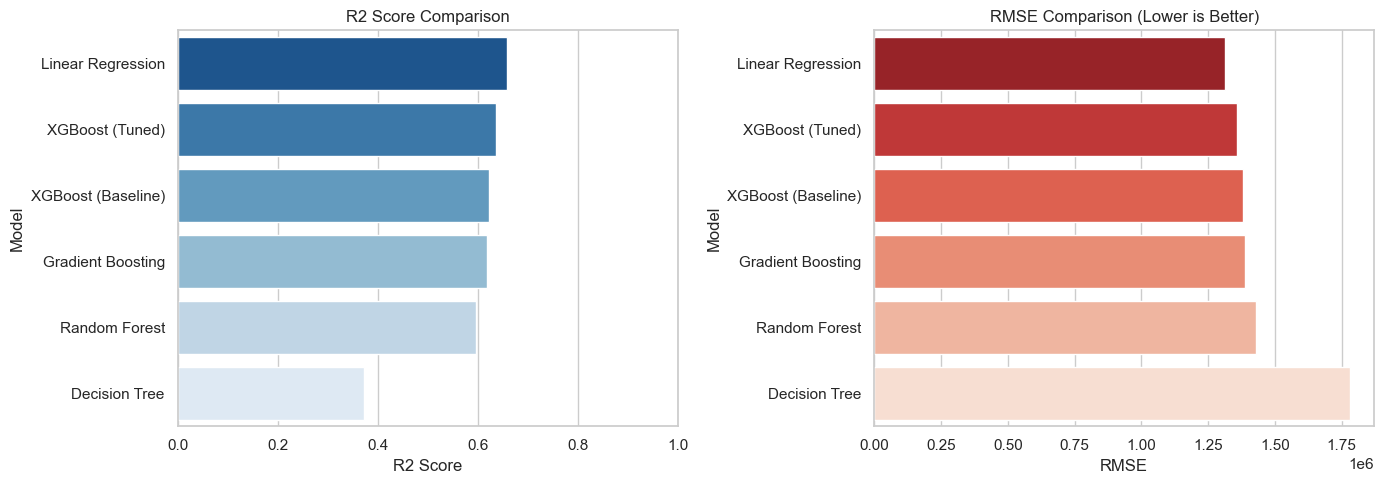

In [12]:
results.append({'Model': 'XGBoost (Tuned)', 'MAE': round(mae, 2), 'RMSE': round(rmse, 2), 'R2 Score': round(r2, 4)})
final_comp_df = pd.DataFrame(results).sort_values(by='R2 Score', ascending=False).reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=final_comp_df, x='R2 Score', y='Model', ax=axes[0], palette='Blues_r', hue='Model', legend=False)
axes[0].set_title('R2 Score Comparison')
axes[0].set_xlim(0, 1)

sns.barplot(data=final_comp_df, x='RMSE', y='Model', ax=axes[1], palette='Reds_r', hue='Model', legend=False)
axes[1].set_title('RMSE Comparison (Lower is Better)')
plt.tight_layout()
plt.show()


## 8. Exporting the Final Production Pipeline
We save the model so that FastAPI backend and prediction scripts can load it directly.


In [13]:
from src.preprocessing import create_full_pipeline, prepare_train_test_data

data_file = os.path.join(BASE_DIR, 'data', 'house_data.csv')
models_dir = os.path.join(BASE_DIR, 'models')
os.makedirs(models_dir, exist_ok=True)

X_train_raw, X_test_raw, y_train_raw, y_test_raw = prepare_train_test_data(data_file)
final_prod_pipeline = create_full_pipeline(best_xgb)
final_prod_pipeline.fit(X_train_raw, y_train_raw)

output_pkl = os.path.join(models_dir, 'model.pkl')
joblib.dump(final_prod_pipeline, output_pkl)
print(f'Final end-to-end production model saved to {output_pkl}')


Final end-to-end production model saved to d:\HOUSE PRICE PREDICTION FOR 7TH SEM\models\model.pkl
